<a href="https://colab.research.google.com/github/unknown-here-now/TIRTC_project/blob/main/Health_Analysis_TIRTC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1. DATASET OVERVIEW ---
Total Rows (Patients): 5190
Total Columns: 13

First 5 Records:
   Unnamed: 0  visits  gender   age  income  illness  reduced  health private  \
0           1       1  female  0.19    0.55        1        4       1     yes   
1           2       1  female  0.19    0.45        1        2       1     yes   
2           3       1    male  0.19    0.90        3        0       0      no   
3           4       1    male  0.19    0.15        1        0       0      no   
4           5       1    male  0.19    0.45        2        5       1      no   

  freepoor freerepat nchronic lchronic  
0       no        no       no       no  
1       no        no       no       no  
2       no        no       no       no  
3       no        no       no       no  
4       no        no      yes       no  

--- 2. DATA CLEANING ---
Missing values count per column:
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private    

/tmp/ipykernel_551/3380947584.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='visits', palette='viridis')


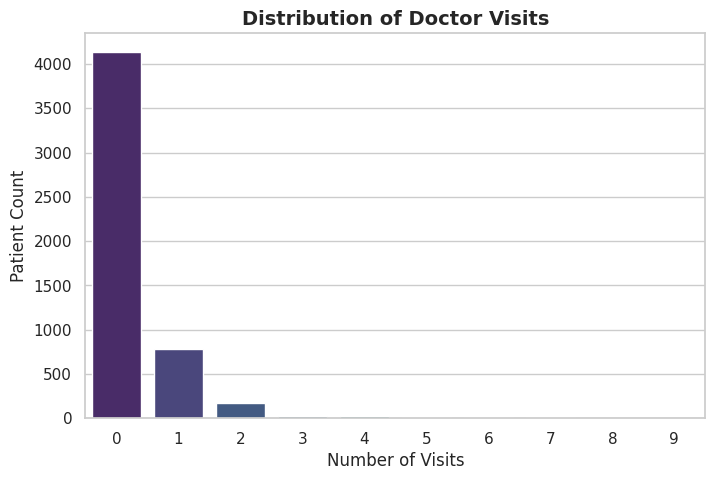

/tmp/ipykernel_551/3380947584.py:52: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='gender', y='visits', palette='Set2', ci=None)
/tmp/ipykernel_551/3380947584.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='gender', y='visits', palette='Set2', ci=None)


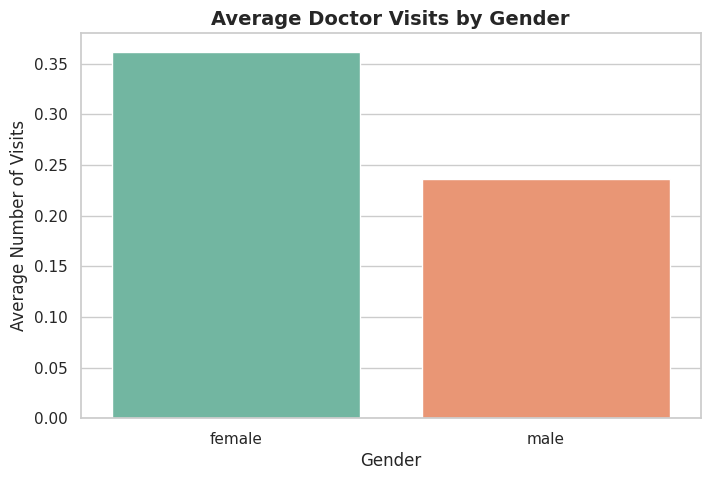

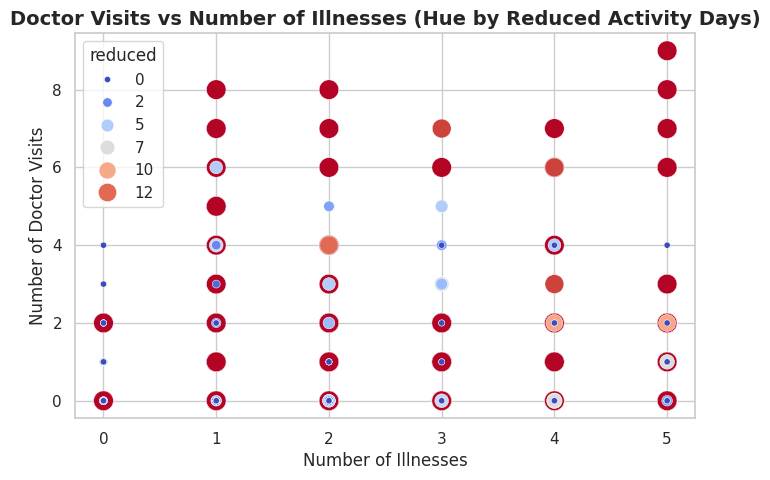

/tmp/ipykernel_551/3380947584.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='private', y='visits', ax=axes[0], palette='Blues')
/tmp/ipykernel_551/3380947584.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='freepoor', y='visits', ax=axes[1], palette='Greens')
/tmp/ipykernel_551/3380947584.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='freerepat', y='visits', ax=axes[2], palette='Oranges')


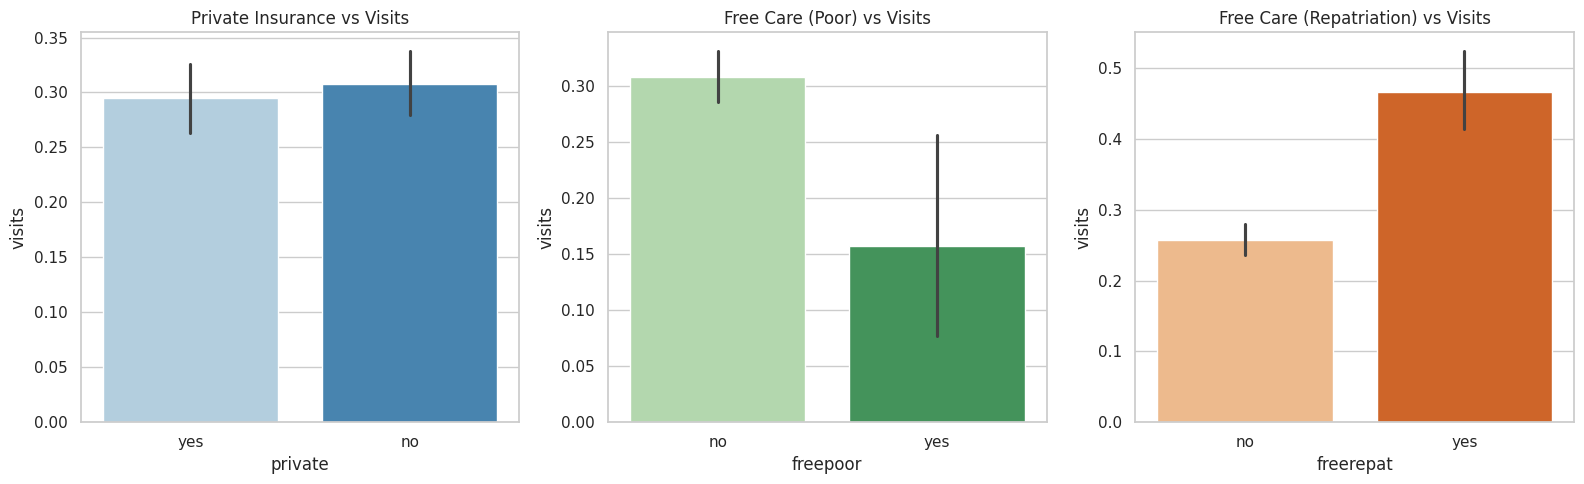

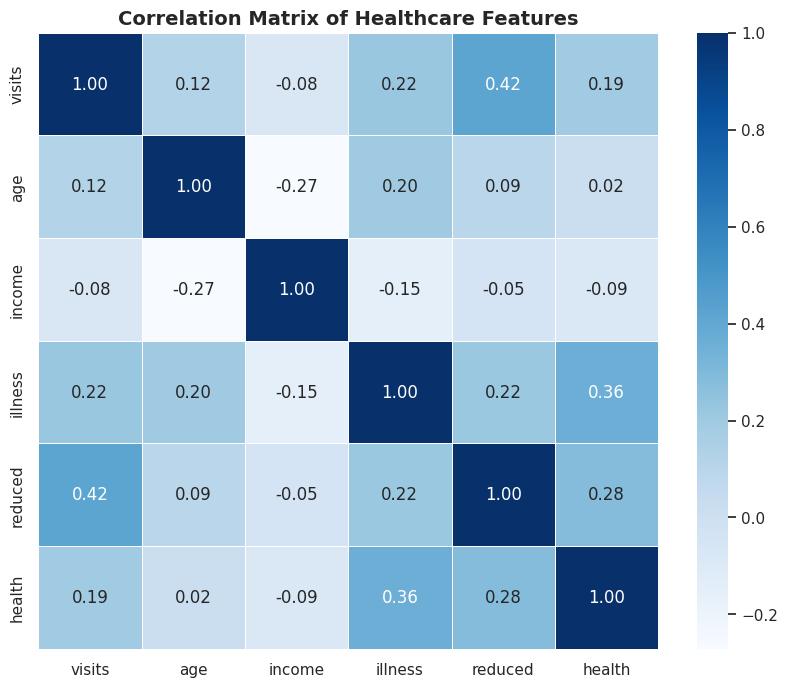


--- 4. KEY INSIGHTS FOR PROJECT REPORT ---
1. Most patients (79.79%) made 0 visits during the recorded period.
2. Patients with long-term chronic conditions average 0.6 visits vs 0.26 visits for those without.
3. Repatriation healthcare recipients (freerepat) show significantly higher visit frequency (0.47 average visits).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. LOAD DATASET
file_name = '1776250375-P2-Healthcare Analytics for Doctor Visits.csv'
df = pd.read_csv(file_name)

print("--- 1. DATASET OVERVIEW ---")
print(f"Total Rows (Patients): {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nFirst 5 Records:")
print(df.head())

# 2. DATA CLEANING & PREPROCESSING
print("\n--- 2. DATA CLEANING ---")
# Drop the redundant identifier column
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Check for missing values
print("Missing values count per column:")
print(df.isnull().sum())

# Data summary statistics
print("\nSummary Statistics:")
print(df.describe())

# 3. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATIONS

# Chart 1: Distribution of Doctor Visits
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='visits', palette='viridis')
plt.title('Distribution of Doctor Visits', fontsize=14, fontweight='bold')
plt.xlabel('Number of Visits')
plt.ylabel('Patient Count')
plt.savefig('distribution_of_visits.png', bbox_inches='tight')
plt.show()

# Chart 2: Doctor Visits by Gender
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='gender', y='visits', palette='Set2', ci=None)
plt.title('Average Doctor Visits by Gender', fontsize=14, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Average Number of Visits')
plt.savefig('visits_by_gender.png', bbox_inches='tight')
plt.show()

# Chart 3: Correlation between Illnesses, Reduced Activity Days, and Visits
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='illness', y='visits', hue='reduced', size='reduced', sizes=(20, 200), palette='coolwarm')
plt.title('Doctor Visits vs Number of Illnesses (Hue by Reduced Activity Days)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Illnesses')
plt.ylabel('Number of Doctor Visits')
plt.savefig('illness_vs_visits.png', bbox_inches='tight')
plt.show()

# Chart 4: Doctor Visits across Insurance & Financial Support Types
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=df, x='private', y='visits', ax=axes[0], palette='Blues')
axes[0].set_title('Private Insurance vs Visits')

sns.barplot(data=df, x='freepoor', y='visits', ax=axes[1], palette='Greens')
axes[1].set_title('Free Care (Poor) vs Visits')

sns.barplot(data=df, x='freerepat', y='visits', ax=axes[2], palette='Oranges')
axes[2].set_title('Free Care (Repatriation) vs Visits')

plt.tight_layout()
plt.savefig('healthcare_support_vs_visits.png', bbox_inches='tight')
plt.show()

# Chart 5: Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Healthcare Features', fontsize=14, fontweight='bold')
plt.savefig('correlation_matrix.png', bbox_inches='tight')
plt.show()

# 4. KEY FINDINGS & INSIGHTS
print("\n--- 4. KEY INSIGHTS FOR PROJECT REPORT ---")
print(f"1. Most patients ({round((df['visits'] == 0).mean() * 100, 2)}%) made 0 visits during the recorded period.")
print(f"2. Patients with long-term chronic conditions average {round(df[df['lchronic']=='yes']['visits'].mean(), 2)} visits vs {round(df[df['lchronic']=='no']['visits'].mean(), 2)} visits for those without.")
print(f"3. Repatriation healthcare recipients (freerepat) show significantly higher visit frequency ({round(df[df['freerepat']=='yes']['visits'].mean(), 2)} average visits).")